# SafeRoute 3D — Faz 1: Veri Setinin Keşfi

## 1. Projenin amacı

SafeRoute 3D, New York City'de **polise raporlanmış** motorlu taşıt kazalarının mekânsal yoğunlaşmalarını
denetimsiz öğrenme (DBSCAN; karşılaştırma için K-Means ve HDBSCAN) ile keşfetmeyi ve sonuçları
coğrafi olarak hizalı 3B bir şehir haritasında yorumlamayı amaçlar.

Bu defter **Faz 1** kapsamındadır: resmi veriyi izlenebilir biçimde elde etmek, yapısını ve kalitesini
ölçmek, özellik adaylarını gerekçelendirmek. Bu fazda **veri temizlenmez ve hiçbir model eğitilmez**.

> Önemli ilke: Kaza yoğunluğu kendi başına risk değildir. Trafik hacmi, yaya sayısı gibi maruziyet
> ölçüleri olmadan "yoğun bölge" ifadesi "daha çok kaza **kaydedilen** bölge" anlamına gelir.

Bu defterdeki **tüm sayılar hücre çıktılarında gerçek veriden hesaplanır**; markdown metinlerinde elle
yazılmış istatistik yoktur.

## 2. Resmi veri seti

- **Ad:** Motor Vehicle Collisions – Crashes
- **Kimlik:** `h9gi-nx95` — https://data.cityofnewyork.us/d/h9gi-nx95
- **Katalog:** https://catalog.data.gov/dataset/motor-vehicle-collisions-crashes
- **Yayıncı / atıf:** NYC Open Data, New York Police Department (NYPD)
- **Birim:** Her satır, polise bildirilmiş **bir kaza olayıdır** (kişi veya araç düzeyinde değil).

Veri, Socrata SODA API'sinden `saferoute download` komutuyla indirildi. Yöntem ayrıntıları
`docs/dataset_provenance.md` dosyasındadır.

In [1]:
import json, time, tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

from saferoute import config
from saferoute.data.loader import latest_snapshot, load_raw, read_manifest, verify_snapshot
from saferoute.data.validate import check_schema
from saferoute.data.metadata import acquisition_record
from saferoute.eda import profile as prof, figures
from saferoute.eda.dictionary import FIELD_INFO, USAGE_LABELS
from saferoute.perf import peak_memory_mb

pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
FIG_DIR = Path(tempfile.mkdtemp(prefix="saferoute_nb_"))   # defter şekilleri geçici dizine çizilir

def show(path):
    display(Image(filename=str(path)))

SNAPSHOT = latest_snapshot()
print("Anlık görüntü:", SNAPSHOT.name)

Anlık görüntü: snapshot_20261019T155113Z


## 3. Veri kökeni (provenance)

Ham veri git'e girmez; onu tanımlayan **manifest** (sayfa bazlı SHA-256, kaynak sürümü, sunucu sayımı)
ve **edinim kaydı** depoda izlenir. Aşağıdaki tablo manifestten okunur.

In [2]:
manifest = read_manifest(SNAPSHOT)
rec = acquisition_record(SNAPSHOT)
prov = pd.Series({
    "Veri seti": f"{manifest['dataset_name']} ({manifest['dataset_id']})",
    "API uç noktası": manifest["download_method"]["endpoint"],
    "Yöntem": f"{manifest['download_method']['api']}, {manifest['download_method']['ordering']}, "
              f"sayfa={manifest['download_method']['page_size']:,}",
    "İndirme (UTC)": f"{manifest['started_at']} → {manifest['completed_at']}",
    "Kaynak rowsUpdatedAt": manifest["source_version"]["rows_updated_at_after"],
    "Beyan edilen güncelleme sıklığı": manifest["source_version"]["update_frequency"],
    "İndirilen satır": f"{manifest['row_count']:,}",
    "Sunucu sayımı": f"{manifest['server_stats_after']['row_count']:,}",
    "Edinim durumu": rec["acquisition_status"],
    "Birleşik SHA-256": manifest["combined_sha256"],
    "Parça sayısı": len(manifest["parts"]),
    "Uyarılar": "; ".join(manifest["warnings"]) or "yok",
}, name="Değer")
prov.to_frame()

,Değer
Veri seti,Motor Vehicle Collisions - Crashes (h9gi-nx95)
API uç noktası,https://data.cityofnewyork.us/resource/h9gi-nx95.csv
Yöntem,"Socrata SODA 2.x (CSV), $order=:id, sayfa=250,000"
İndirme (UTC),2026-10-19T15:51:15.156697+00:00 → 2026-10-19T16:01:15.101443+00:00
Kaynak rowsUpdatedAt,2026-06-15T23:05:47+00:00
Beyan edilen güncelleme sıklığı,Daily
İndirilen satır,"2,269,187"
Sunucu sayımı,"2,269,187"
Edinim durumu,full
Birleşik SHA-256,2fe1297c24f7aad761bca1dc3c04ec0de3459d297e06af20fbfe5e35ad10be5e


In [3]:
# Kaynağın güncelliği: en son kaynak durumu kaydı (saferoute check-source)
status_files = sorted(config.METADATA_DIR.glob("source_status_*.json"))
if status_files:
    st = json.loads(status_files[-1].read_text(encoding="utf-8"))
    display(pd.Series(st["freshness"], name=status_files[-1].name).to_frame())
else:
    print("Kaynak durumu kaydı yok; 'saferoute check-source' çalıştırın.")

,source_status_20261019T164047Z.json
rows_updated_at,2026-06-15T23:05:47+00:00
declared_update_frequency,Daily
days_since_rows_updated,125
staleness_threshold_days,3
verdict,stale


## 4. Yükleme süreci

`load_raw` önce her parçanın SHA-256 değerini manifeste göre doğrular, sonra tüm parçaları **tamamı metin
türünde** tek bir Arrow destekli DataFrame'e okur. Yalnızca gerçekten boş CSV alanları eksik (null)
sayılır; `"NA"`, `"NULL"` gibi metinler veri olarak korunur. Tür dönüşümü bilinçli olarak sonraya
bırakılır: böylece "ayrıştırılamayan" değerler sessizce kaybolmaz, sayılabilir.

In [4]:
t0 = time.perf_counter()
df = load_raw(SNAPSHOT, verify=True)
print(f"Yükleme + doğrulama: {time.perf_counter() - t0:.1f} sn")
print(f"DataFrame bellek: {df.memory_usage(deep=True).sum() / 2**20:,.0f} MB; süreç tepe değeri: {peak_memory_mb()} MB")

Yükleme + doğrulama: 1.6 sn
DataFrame bellek: 677 MB; süreç tepe değeri: 1006.5 MB


## 5. Satır ve sütun sayıları

In [5]:
schema = check_schema(df)
print(f"Satır: {len(df):,}   Sütun: {df.shape[1]}")
print("Şema geçerli:", schema.is_valid, "| eksik sütun:", schema.missing_columns,
      "| beklenmeyen sütun:", schema.unexpected_columns, "| sıra beklenenle aynı:", schema.order_matches)
print("Manifest satır sayısıyla eşleşme:", len(df) == manifest["row_count"])

Satır: 2,269,187   Sütun: 29
Şema geçerli: True | eksik sütun: [] | beklenmeyen sütun: [] | sıra beklenenle aynı: True
Manifest satır sayısıyla eşleşme: True


## 6. Sütun açıklamaları

Anlam ve öngörülen kullanım `saferoute.eda.dictionary` içinde tanımlıdır; tür, benzersiz değer ve aday
kimlik bilgileri ölçülür. *Kaynak türü* Socrata meta verisinden, *ölçülen tür* dolu değerlerin
tamamına uyan en dar türden gelir. Aynı tablo `docs/data_dictionary.md` olarak da üretilir.

In [6]:
source_types = {c["field_name"]: c["data_type"] for c in manifest["columns"]}
overview = prof.column_overview(df, source_types)
dictionary = pd.DataFrame([
    {"Sütun": c, "Anlam": FIELD_INFO[c][0], "Kaynak türü": o["source_type"], "Ölçülen tür": o["inferred_type"],
     "Benzersiz (dolu)": o["unique_non_missing"], "Aday kimlik": o["candidate_identifier"],
     "Kullanım": USAGE_LABELS[FIELD_INFO[c][1]]}
    for c, o in overview.items()
])
dictionary

,Sütun,Anlam,Kaynak türü,Ölçülen tür,Benzersiz (dolu),Aday kimlik,Kullanım
0,crash_date,Kaza tarihi,calendar_date,datetime,5094,False,B — Zamansal model özelliği (deneysel) + filtre
1,crash_time,Kaza saati (H:MM),text,time,1440,False,B — Zamansal model özelliği (deneysel) + filtre
2,borough,Kayıtta bildirilen ilçe,text,text,5,False,C — Yalnızca filtre
3,zip_code,Posta kodu,text,integer,235,False,C — Yalnızca filtre
4,latitude,Enlem (WGS84),number,float,189606,False,A — Coğrafi model özelliği
5,longitude,Boylam (WGS84),number,float,141342,False,A — Coğrafi model özelliği
6,location,"'(enlem, boylam)' metni",location,text,397985,False,E — Kimlik / model dışı
7,on_street_name,Kazanın olduğu cadde,text,text,23331,False,D — Betimleyici / sonuç
8,off_street_name,Kesişen/yakın cadde,text,text,25403,False,D — Betimleyici / sonuç
9,cross_street_name,Çapraz sokak / adres metni,text,text,271299,False,D — Betimleyici / sonuç


## 7. Eksik değer analizi

İki tür eksiklik ayrı sayılır: **null** (alan tamamen boş) ve **yalnız boşluk** (dolu görünen ama yalnızca
boşluk içeren alan). Eksik değerler bu fazda **doldurulmaz**.

In [7]:
mv = pd.DataFrame(prof.missing_values(df)).T.sort_values("missing_pct", ascending=False)
mv.columns = ["Null", "Yalnız boşluk", "Toplam eksik", "Eksik %"]
mv = mv.astype({"Null": int, "Yalnız boşluk": int, "Toplam eksik": int})
mv

,Null,Yalnız boşluk,Toplam eksik,Eksik %
vehicle_type_code_5,2259199,0,2259199,99.5598
contributing_factor_vehicle_5,2258873,0,2258873,99.5455
vehicle_type_code_4,2232943,0,2232943,98.4028
contributing_factor_vehicle_4,2231554,0,2231554,98.3416
vehicle_type_code_3,2111354,0,2111354,93.0445
contributing_factor_vehicle_3,2104798,0,2104798,92.7556
cross_street_name,1862382,29,1862411,82.0739
off_street_name,870147,17,870164,38.3469
zip_code,691661,42,691703,30.4824
borough,691375,0,691375,30.4680


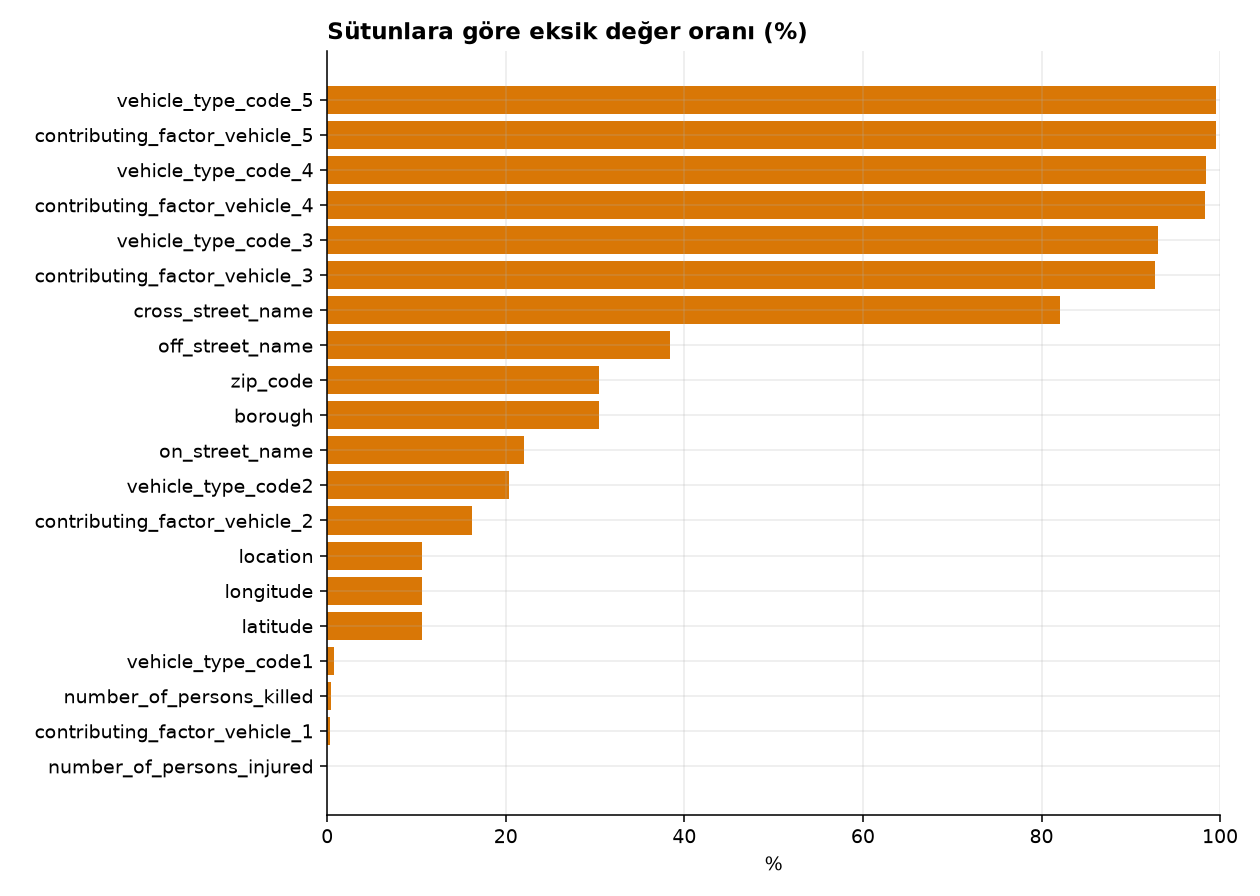

In [8]:
profile = {"missing_values": prof.missing_values(df)}
show(figures.plot_missing(profile, FIG_DIR))

**Yorum.** Eksiklik yapısı sütun grubuna göre belirgin biçimde farklıdır: tarih/saat ve kimlik alanları
tam doludur; konum metinleri, ilçe ve posta kodu ise önemli ölçüde eksiktir. Ek araç/faktör sütunlarının
(3–5) yüksek eksikliği bir veri hatası değil, kazaya karışan araç sayısının doğal sonucudur.

## 8. Tarih ve saat analizi

In [9]:
temporal = prof.temporal(df)
summary = {k: v for k, v in temporal.items() if not k.startswith("rows_per")}
pd.Series(summary, name="Değer").to_frame()

,Değer
crash_date_missing,0
crash_date_unparseable,0
crash_date_min,2012-07-01
crash_date_max,2026-06-11
crash_date_has_nonzero_time_component,0
crash_time_missing,0
crash_time_invalid,0
crash_time_exact_midnight,24566
crash_time_exact_midnight_pct,1.0826


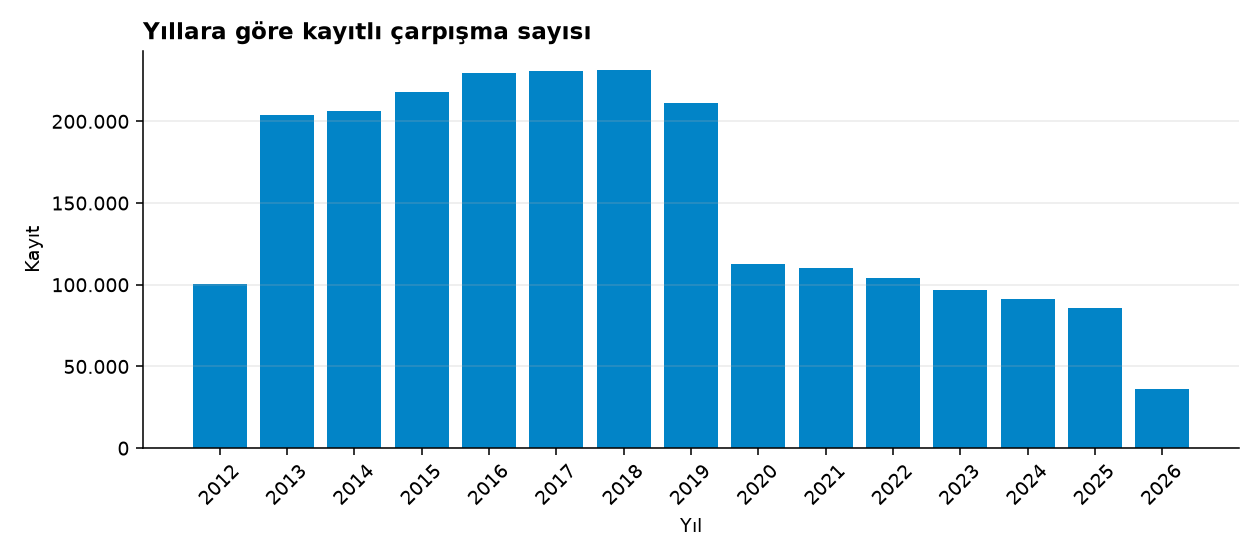

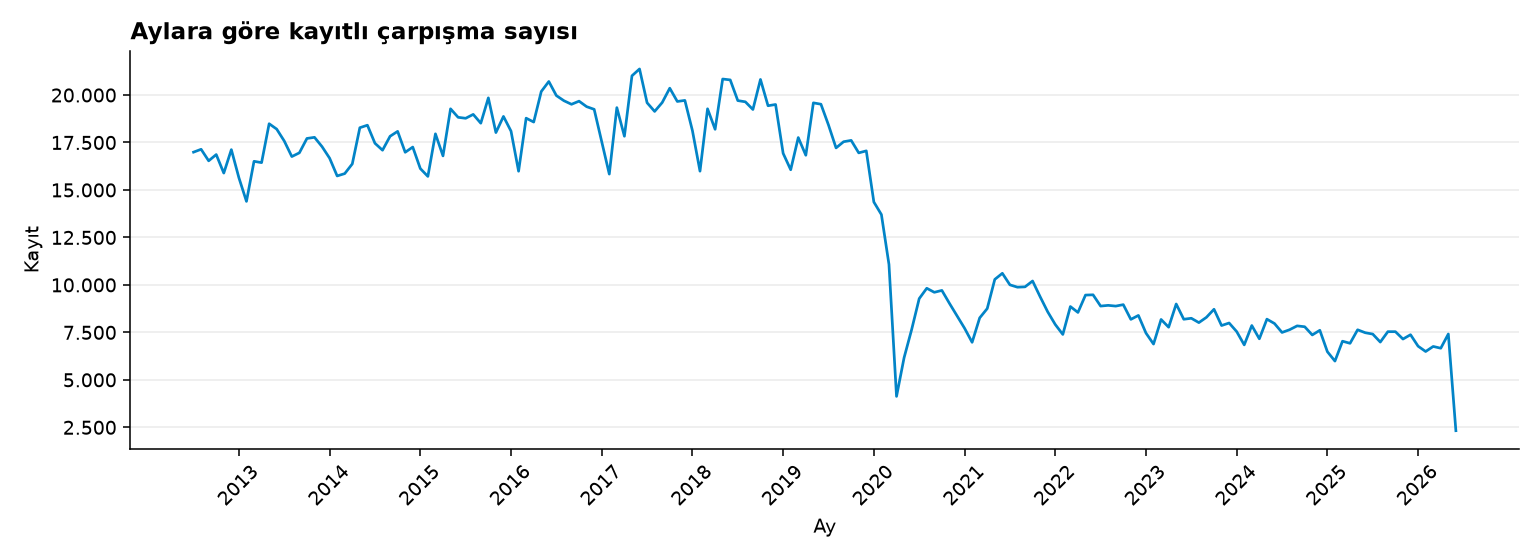

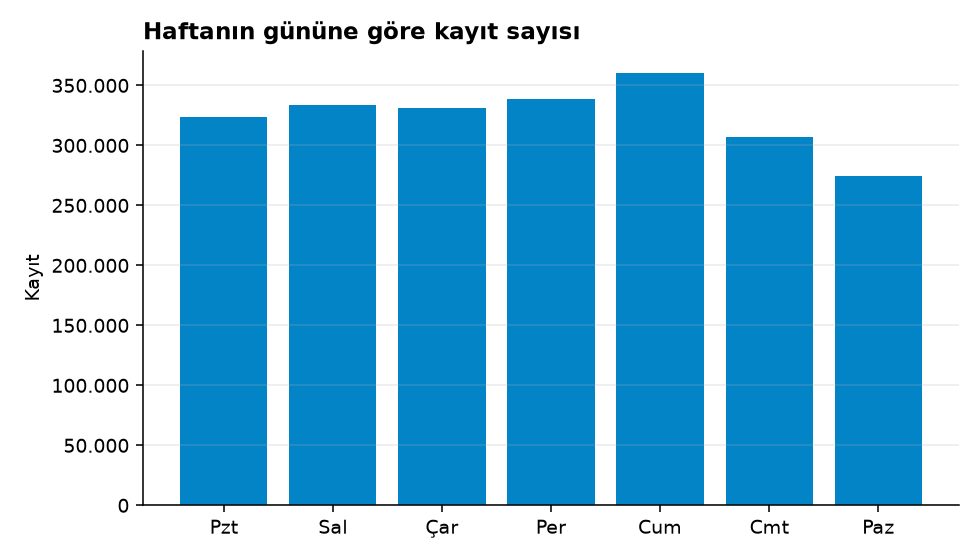

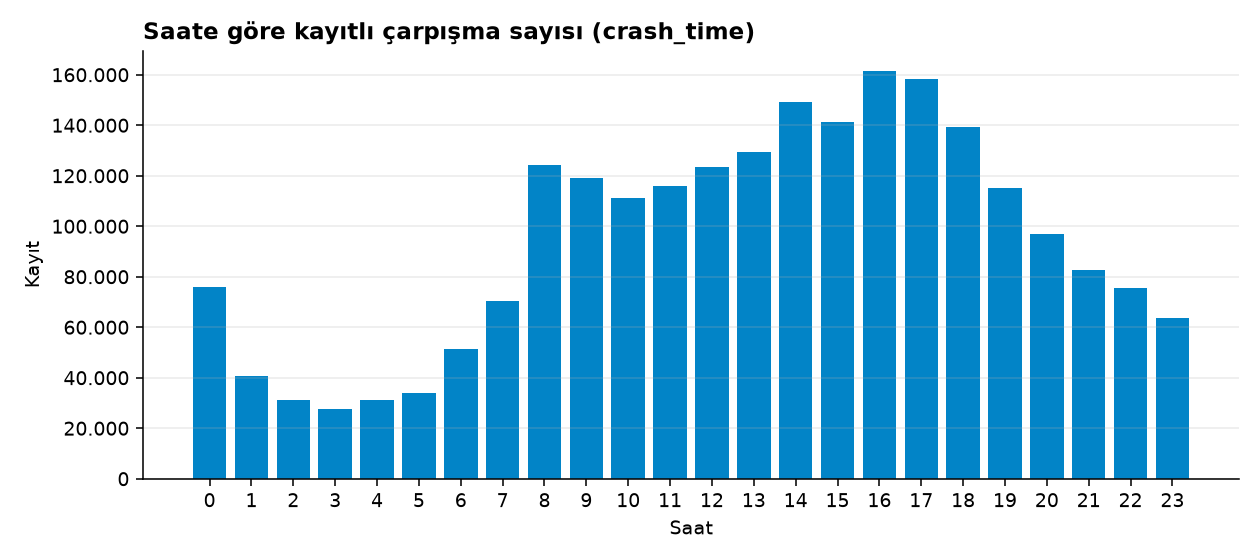

In [10]:
profile["temporal"] = temporal
for fn in (figures.plot_rows_per_year, figures.plot_rows_per_month, figures.plot_rows_per_weekday,
           figures.plot_rows_per_hour):
    show(fn(profile, FIG_DIR))

In [11]:
# Gece yarısı yığılması: 00:00 dakikası, saat 0'ın dakika ortalamasıyla karşılaştırılır
hour0 = temporal["rows_per_hour"].get("0", 0)
midnight = temporal["crash_time_exact_midnight"]
print(f"Saat 0 toplamı: {hour0:,}  -> dakika başına ortalama {hour0 / 60:,.0f}")
print(f"Tam 00:00 kaydı: {midnight:,}  -> ortalamanın {midnight / (hour0 / 60):.1f} katı")
first, last = temporal["crash_date_min"], temporal["crash_date_max"]
print(f"Kapsam: {first} → {last}  (ilk ve son yıl kısmi; tam yıl karşılaştırmasına katılmamalı)")

Saat 0 toplamı: 75,806  -> dakika başına ortalama 1,263
Tam 00:00 kaydı: 24,566  -> ortalamanın 19.4 katı
Kapsam: 2012-07-01 → 2026-06-11  (ilk ve son yıl kısmi; tam yıl karşılaştırmasına katılmamalı)


**Yorum.** Yıllık ve aylık seriler, 2020 başında keskin bir düzey kırılması gösterir; zamanlama COVID-19
dönemiyle örtüşür, ancak bu veri nedensellik kurmaya yetmez ve sonraki yıllarda seri önceki düzeyine
dönmemiştir. Kapsamın ilk ve son yılı kısmidir. 00:00 dakikasındaki yığılma, saat bilinmediğinde
varsayılan değer girilmiş olabileceğini düşündürür; Faz 2'de bu kayıtlar zaman filtrelerinde işaretlenecektir.

## 9. Beş ilçe (borough) analizi

İlçe alanı **kayıtta bildirilen** değerdir. Eksik ilçeli kayıtlar **atılmaz**; ayrı raporlanır.
Bu fazda kaba bir sınırlayıcı kutu ile **ilçe ataması yapılmaz** — kutu yalnızca koordinatın NYC
civarında olup olmadığını test eder.

In [12]:
b = prof.boroughs(df)
counts = pd.Series(b["counts"], name="Kayıt").to_frame()
counts.loc["(eksik)"] = b["missing"]
counts.loc["(beklenmeyen etiket)"] = b["unexpected_rows"]
counts["Oran %"] = (100 * counts["Kayıt"] / len(df)).round(2)
display(counts)
print("Beklenmeyen etiketler:", b["unexpected_values"] or "yok")

,Kayıt,Oran %
MANHATTAN,348485,15.36
BROOKLYN,506806,22.33
QUEENS,422409,18.61
BRONX,234088,10.32
STATEN ISLAND,66024,2.91
(eksik),691375,30.47
(beklenmeyen etiket),0,0.00


Beklenmeyen etiketler: yok


,Eksik,Ayrıştırılamaz,"Sıfır (0,0)",NYC kutusu dışı,Geçerli
MANHATTAN,10097,0,1370,0,337018
BROOKLYN,10437,0,2066,2,494301
QUEENS,8722,0,1600,0,412087
BRONX,6969,0,1067,0,226052
STATEN ISLAND,1650,0,218,0,64156
MISSING,202931,0,1270,148,487026


Geçerli koordinatlı ama ilçesi boş kayıt: 487,026


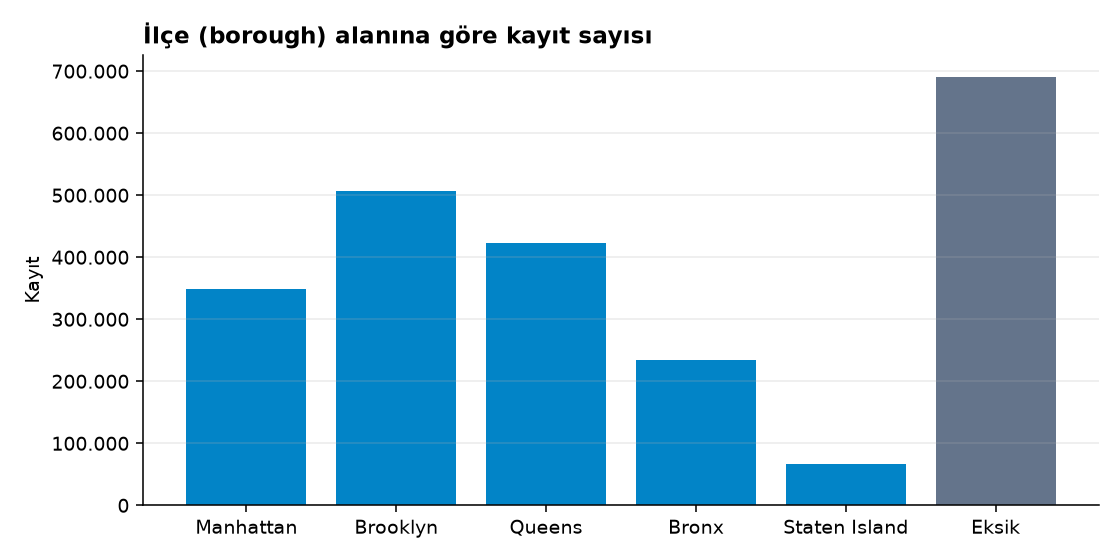

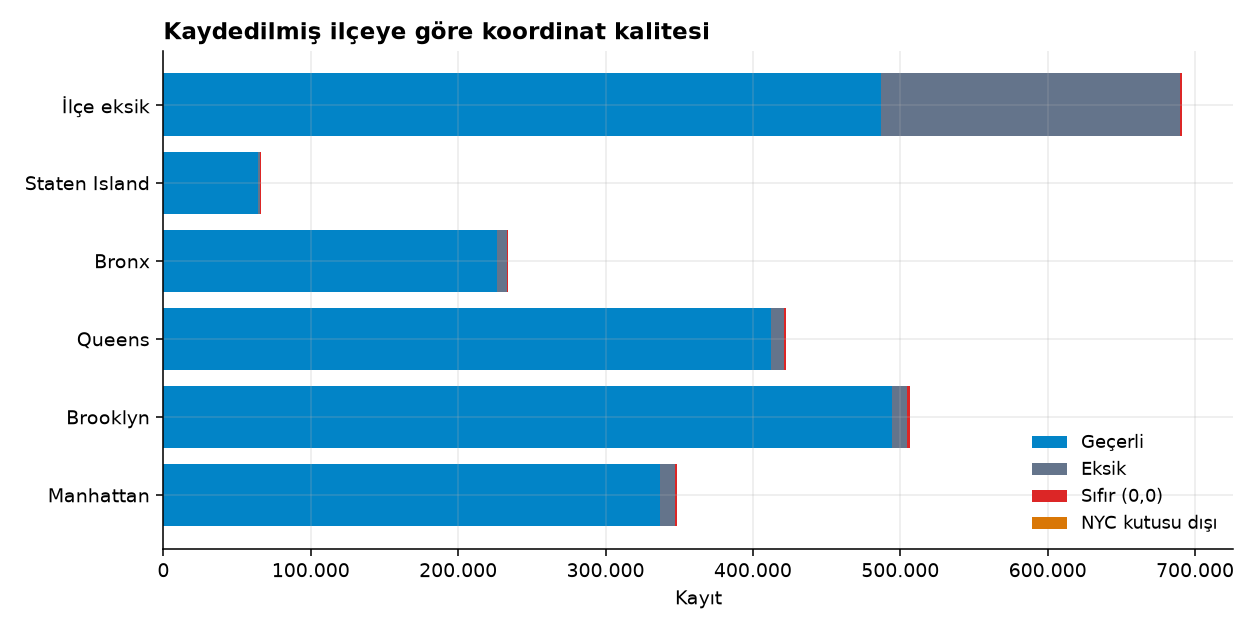

In [13]:
cross = pd.DataFrame(prof.borough_by_coordinate_class(df)).T
cross.columns = [figures.COORD_CLASS_TR[c] for c in cross.columns]
display(cross)
print("Geçerli koordinatlı ama ilçesi boş kayıt:", f"{cross.loc['MISSING', 'Geçerli']:,}")
profile.update({"boroughs": b, "borough_by_coordinate_class": prof.borough_by_coordinate_class(df)})
show(figures.plot_boroughs(profile, FIG_DIR))
show(figures.plot_borough_coordinate_quality(profile, FIG_DIR))

**Yorum.** Beş ilçenin tamamı veride temsil edilmektedir; beklenmeyen etiket yoktur. İlçe alanı boş olan
kayıtların büyük bölümünün koordinatı geçerlidir: bu kayıtlar, Faz 2'de resmi ilçe sınırlarıyla
(NYC DCP *Borough Boundaries*, `gthc-hcne`) **geometrik olarak** zenginleştirilebilir. Bildirilen ve
çıkarılan ilçe ayrı sütunlarda tutulacaktır.

## 10. Yaralanma ve ölüm özetleri

,missing,unparseable,negative,non_integer,sum,max,rows_gt_zero
number_of_persons_injured,18,0,0,0,756353,43.0,558603
number_of_persons_killed,8913,0,0,0,3617,8.0,3469
number_of_pedestrians_injured,0,0,0,0,137819,27.0,132157
number_of_pedestrians_killed,0,0,0,0,1805,6.0,1778
number_of_cyclist_injured,0,0,0,0,67336,4.0,66461
number_of_cyclist_killed,0,0,0,0,294,2.0,293
number_of_motorist_injured,0,0,0,0,540227,43.0,353245
number_of_motorist_killed,0,0,0,0,1466,5.0,1355


,Yaralı,Ölü
comparable_rows,2269169,2260274
persons_equals_sum,2258255,2260190
persons_greater_than_sum,10687,78
persons_less_than_sum,227,6


En az bir yaralı olan kayıt: 558,603; en az bir ölü olan kayıt: 3,469


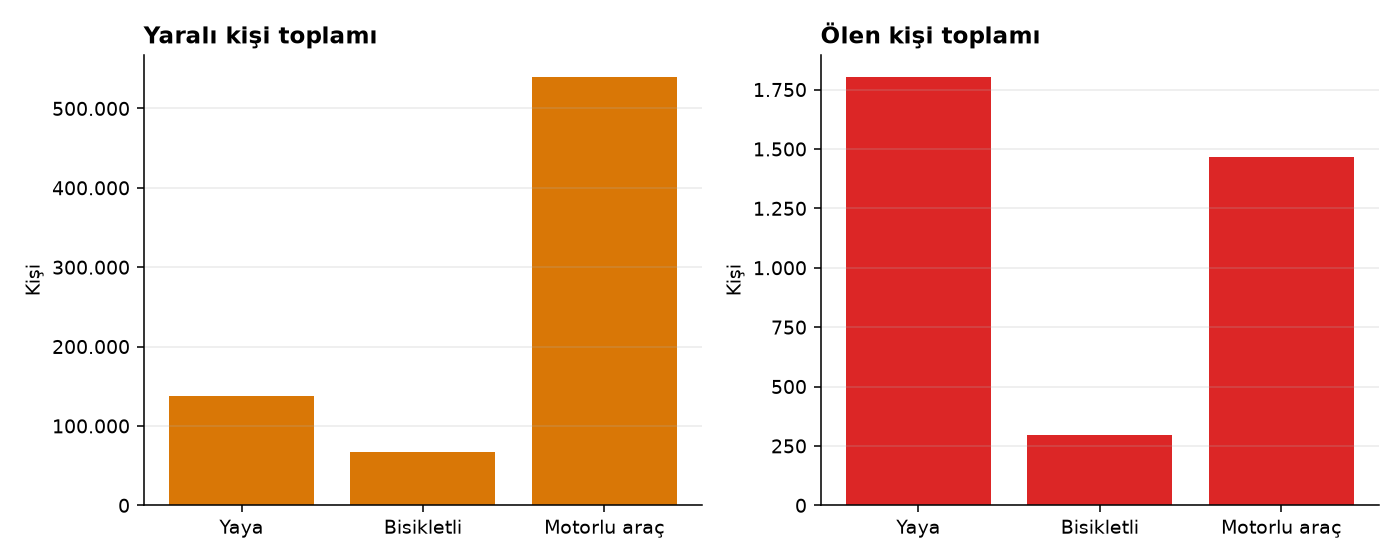

In [14]:
cas = prof.casualties(df)
cas_table = pd.DataFrame(cas["columns"]).T
int_cols = ["missing", "unparseable", "negative", "non_integer", "sum", "rows_gt_zero"]
cas_table[int_cols] = cas_table[int_cols].astype(int)
display(cas_table)
display(pd.DataFrame({"Yaralı": cas["consistency_injured"], "Ölü": cas["consistency_killed"]}))
print(f"En az bir yaralı olan kayıt: {cas['rows_with_any_injury']:,}; en az bir ölü olan kayıt: {cas['rows_with_any_fatality']:,}")
profile["casualties"] = cas
show(figures.plot_casualties(profile, FIG_DIR))

**Yorum.** Ölümlü kazalar nadirdir; yaralanmalı kazalar ise kayıtların önemli bir kesimini oluşturur.
"Kişi toplamı = yaya + bisikletli + motorlu" eşitliği kayıtların çok büyük kısmında sağlanır, ancak
tutarsız kayıtlar vardır; Faz 2'de bunlar düzeltilmeden **işaretlenecek** ve hangi sütunun esas alınacağı
belgelenecektir.

**Neden yaralı/ölü sayıları küme üyeliğini belirlememeli?** İlk deneylerin sorusu "kazalar mekânda nerede
yoğunlaşıyor?" sorusudur. Ağırlık veya özellik olarak yaralanma sayısı eklemek kümelerin anlamını
"şiddet-ağırlıklı yoğunluk"a çevirir, nadir ve gürültülü ölüm sayıları küme sınırlarını orantısız
etkiler ve sonra aynı değişkenle kümeleri "değerlendirmek" döngüsel bir akıl yürütme olur. Bu nedenle
bu alanlar önce **betimleyici** olarak (kümelerin yaralanma/ölüm profili) kullanılacaktır.

## 11. Araç türü ve katkıda bulunan faktör analizi

Araç türü farklı değer: ham 3,149 -> normalize 2,168
Faktör (araç 1) 'Unspecified': 756,643 (%33.34)


,Kayıt
Dolu araç türü sütunu,
0,17081
1,446026
2,1648247
3,121589
4,26256
5,9988


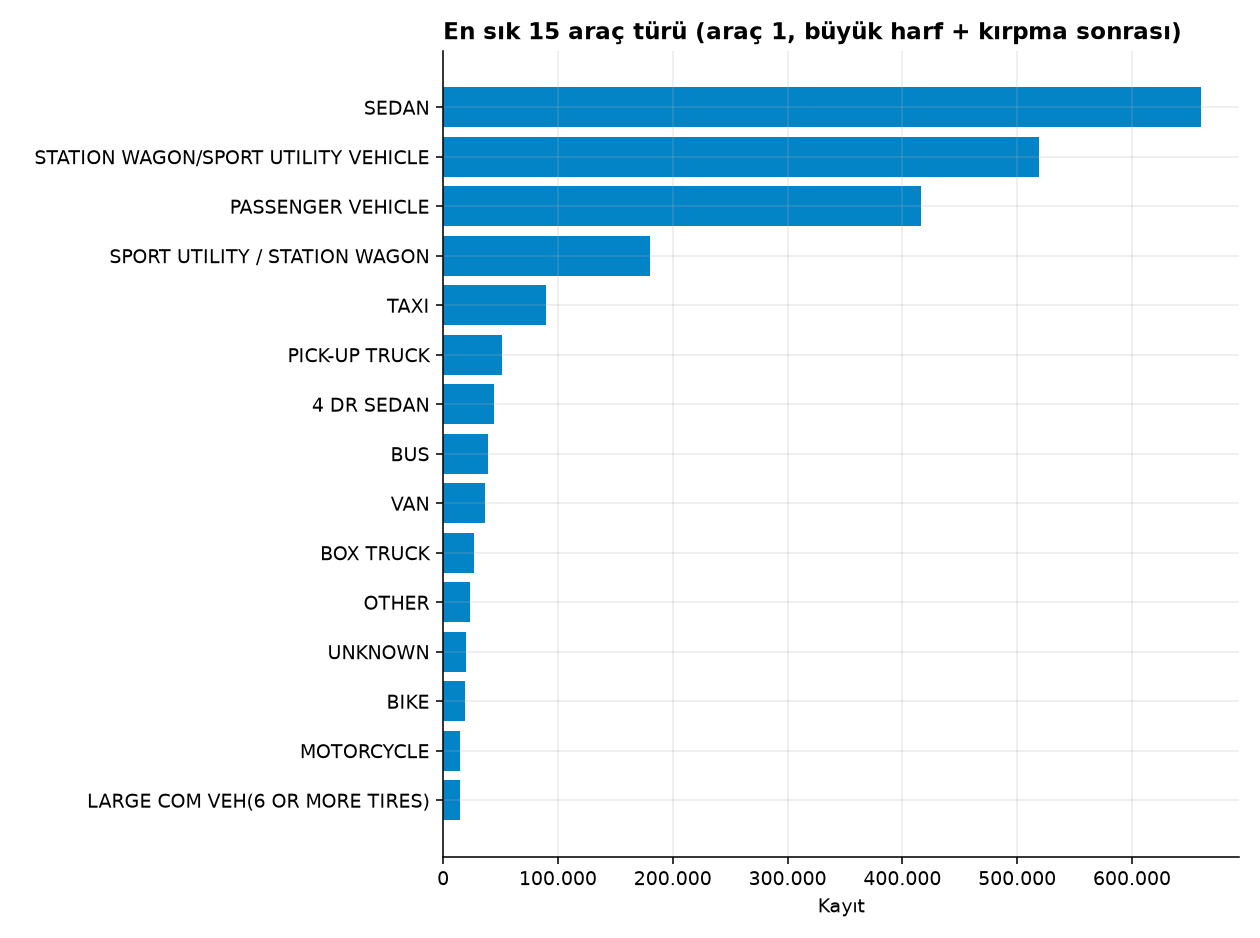

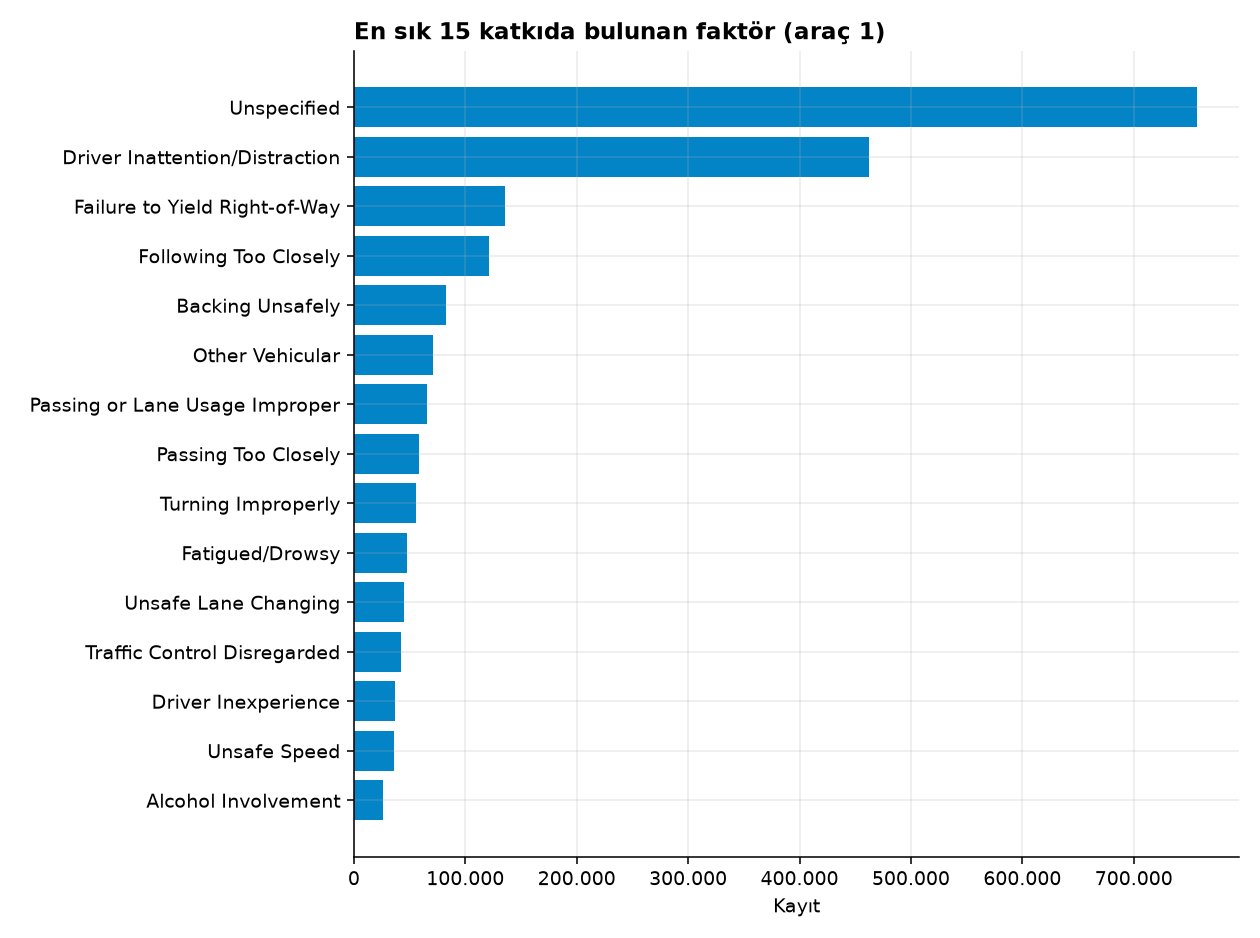

In [15]:
cat = prof.categoricals(df)
print(f"Araç türü farklı değer: ham {cat['vehicle_type_distinct_raw']:,} -> normalize {cat['vehicle_type_distinct_normalized']:,}")
print(f"Faktör (araç 1) 'Unspecified': {cat['contributing_factor_1_unspecified']:,} (%{cat['contributing_factor_1_unspecified_pct']:.2f})")
display(pd.Series(cat["vehicle_type_codes_present_per_row"], name="Kayıt").rename_axis("Dolu araç türü sütunu").to_frame())
profile["categoricals"] = cat
show(figures.plot_vehicle_types(profile, FIG_DIR))
show(figures.plot_top_factors(profile, FIG_DIR))

**Yorum.** Araç türü alanında aynı kavram için birden çok adlandırma şeması bir arada bulunur
(ör. *SEDAN*, *4 DR SEDAN*, *PASSENGER VEHICLE*). Bu alan filtre olarak kullanılmadan önce belgelenmiş bir
kategori eşleme tablosu gerekir. Faktör alanında "Unspecified" çok yaygındır; bu değer bir neden değil
"bilinmiyor" olarak ele alınmalıdır.

## 12. Coğrafi veri kalitesi

Koordinatlar birbirini dışlayan beş sınıfa ayrılır: **eksik → ayrıştırılamaz → sıfır (0,0) →
NYC kutusu dışı → geçerli**. Eksik koordinatlar sıfırla doldurulmaz; sıfır ve kutu dışı değerler
**geçersiz** sayılır ama ham kayıt korunur. Yoğunluk haritası, geçerli koordinatlı kayıtların
**tamamından** (örnekleme olmadan) altıgen hücre sayımıyla çizilir.

In [16]:
coords = prof.coordinates(df)
cls = pd.DataFrame({"Kayıt": coords["classes"], "Oran %": coords["classes_pct"]})
cls.index = [figures.COORD_CLASS_TR[i] for i in cls.index]
display(cls)
extra = {k: coords[k] for k in ("valid_but_borough_missing", "borough_present_but_coords_unusable",
                                "location_present_latlon_missing", "latlon_present_location_missing",
                                "distinct_valid_locations")}
display(pd.Series(extra, name="Kayıt").to_frame())
print("Geçerli noktaların kapsamı:", coords["valid_extent"])

,Kayıt,Oran %
Eksik,240806,10.6120
Ayrıştırılamaz,0,0.0000
"Sıfır (0,0)",7591,0.3345
NYC kutusu dışı,150,0.0066
Geçerli,2020640,89.0469


,Kayıt
valid_but_borough_missing,487026
borough_present_but_coords_unusable,44198
location_present_latlon_missing,0
latlon_present_location_missing,0
distinct_valid_locations,349124


Geçerli noktaların kapsamı: {'min_lat': 40.498947, 'max_lat': 40.912884, 'min_lon': -74.25496, 'max_lon': -73.70048}


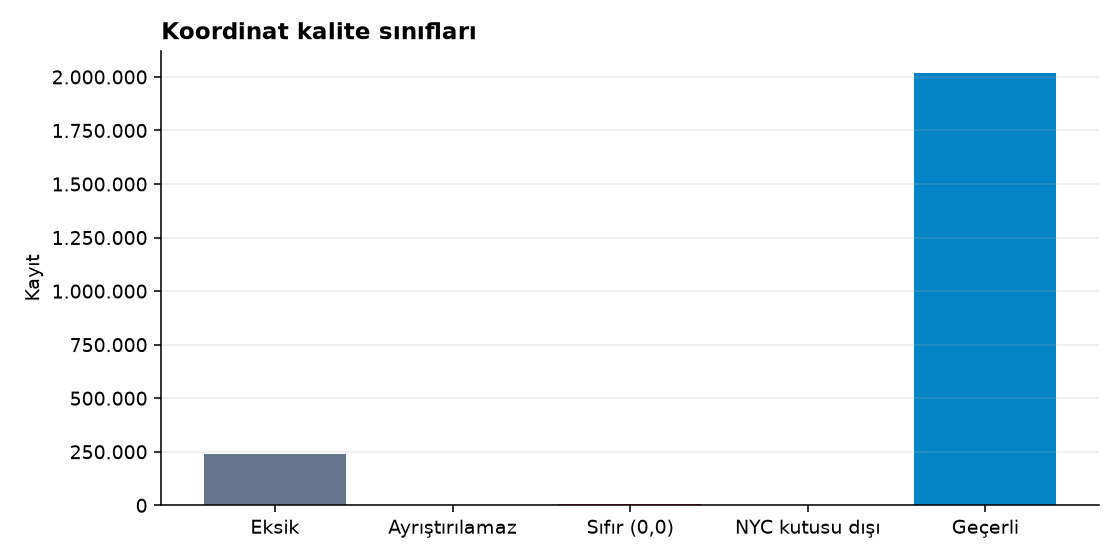

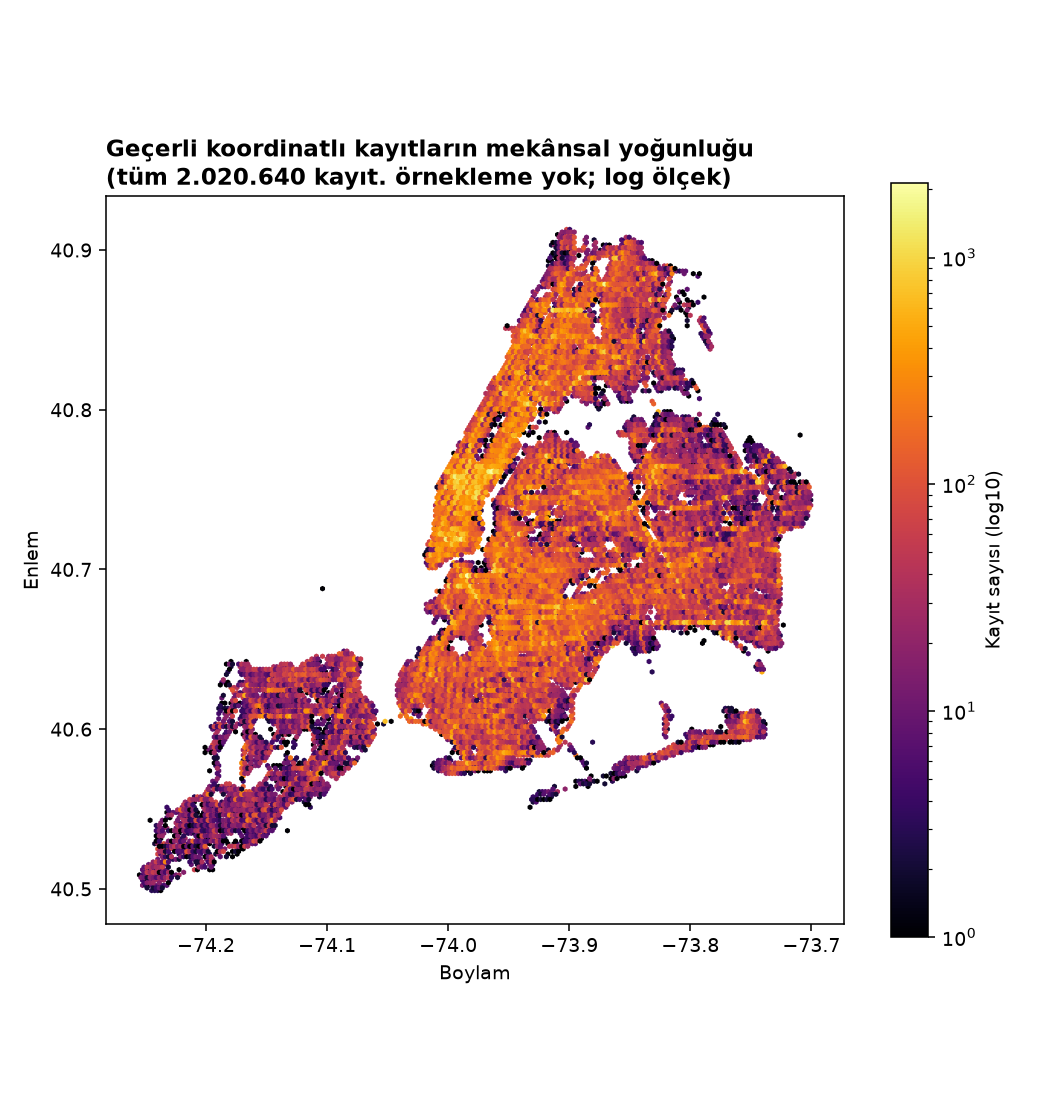

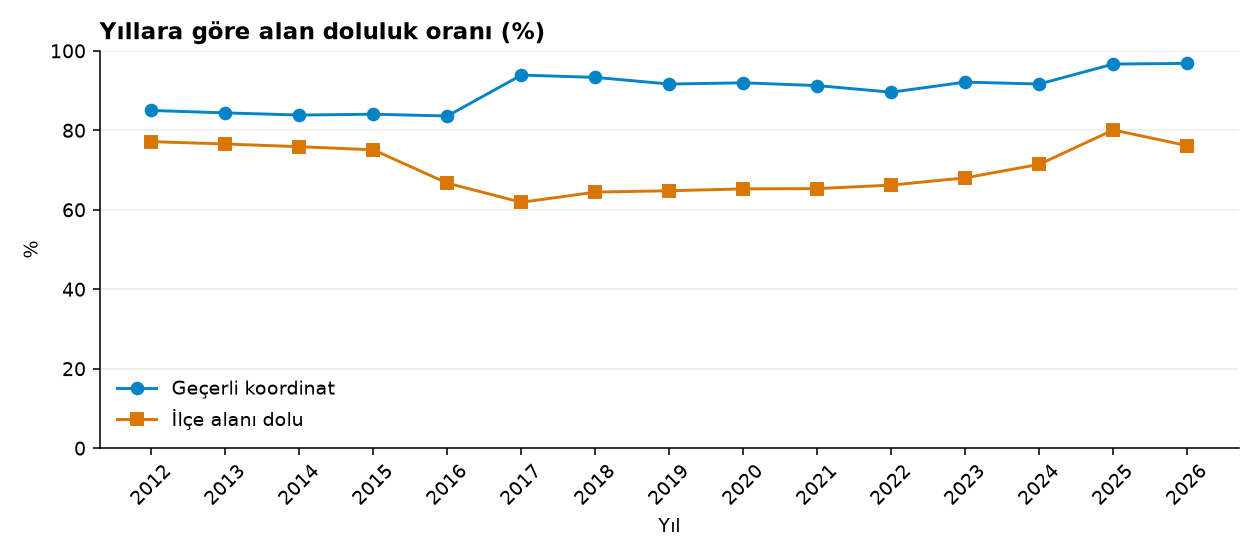

Geçerli nokta / farklı konum oranı: 5.8 (aynı koordinatta çok sayıda kayıt)


In [17]:
profile.update({"coordinates": coords, "quality_by_year": prof.by_year_quality(df)})
mask = prof.coordinate_validity_mask(df)
lat = prof._numeric(df.loc[mask, "latitude"]).to_numpy()
lon = prof._numeric(df.loc[mask, "longitude"]).to_numpy()
show(figures.plot_coordinate_classes(profile, FIG_DIR))
show(figures.plot_hexbin(lat, lon, FIG_DIR))
show(figures.plot_quality_by_year(profile, FIG_DIR))
ratio = coords["classes"]["valid_in_bbox"] / coords["distinct_valid_locations"]
print(f"Geçerli nokta / farklı konum oranı: {ratio:.1f} (aynı koordinatta çok sayıda kayıt)")

**Yorum.** Kayıtların büyük çoğunluğunun koordinatı geçerlidir. Geçerli noktalar az sayıda farklı konuma
yığılmıştır (büyük olasılıkla kavşak merkezlerine kodlama): bu, DBSCAN'de `min_samples` yorumunu
doğrudan etkiler ve aynı noktaların ağırlıklandırılmasıyla hesaplama maliyetinin düşürülmesine imkân
verir. Dikdörtgen kutu kaba bir testtir — New Jersey'nin bazı kısımlarını ve su alanlarını da kapsar;
kesin sınır kontrolü Faz 2'de ilçe poligonlarıyla yapılacaktır. Geçerli koordinat ve ilçe doluluk
oranları yıllara göre değişmektedir; yıllar arası karşılaştırmalarda bu kalite farkı dikkate alınmalıdır.

## 13. Özelliklerin dahil edilmesi / dışlanması

Ayrıntılı gerekçe `docs/feature_candidates.md` dosyasındadır. Özet sınıflandırma:

- **A — Coğrafi model özellikleri:** `latitude`, `longitude` (radyana çevrilip Haversine; K-Means için metrik projeksiyon)
- **B — Zamansal model özellikleri (deneysel):** `crash_date`, `crash_time` — yalnızca açıkça tanımlanmış bir uzay-zaman uzaklığıyla
- **C — Yalnızca filtre:** ilçe, posta kodu, araç türü, katkıda bulunan faktör
- **D — Betimleyici / sonuç:** yaralı/ölü sayıları, sokak adları
- **E — Kimlik / model dışı:** `collision_id`, `location` (enlem/boylamın tekrarı)

In [18]:
groups = dictionary.groupby("Kullanım")["Sütun"].apply(list)
for usage, cols in groups.items():
    print(f"{usage}:\n   " + ", ".join(cols))

A — Coğrafi model özelliği:
   latitude, longitude
B — Zamansal model özelliği (deneysel) + filtre:
   crash_date, crash_time
C — Yalnızca filtre:
   borough, zip_code, contributing_factor_vehicle_1, contributing_factor_vehicle_2, contributing_factor_vehicle_3, contributing_factor_vehicle_4, contributing_factor_vehicle_5, vehicle_type_code1, vehicle_type_code2, vehicle_type_code_3, vehicle_type_code_4, vehicle_type_code_5
D — Betimleyici / sonuç:
   on_street_name, off_street_name, cross_street_name, number_of_persons_injured, number_of_persons_killed, number_of_pedestrians_injured, number_of_pedestrians_killed, number_of_cyclist_injured, number_of_cyclist_killed, number_of_motorist_injured, number_of_motorist_killed
E — Kimlik / model dışı:
   location, collision_id


## 14. İlk sonuçlar (ölçülen değerlerle)

In [19]:
key = pd.Series({
    "Toplam kayıt": f"{len(df):,}",
    "Tarih kapsamı": f"{temporal['crash_date_min']} → {temporal['crash_date_max']}",
    "Benzersiz collision_id": f"{prof.duplicates(df)['collision_id_unique_values']:,}",
    "Geçerli koordinat": f"{coords['classes']['valid_in_bbox']:,} (%{coords['classes_pct']['valid_in_bbox']:.2f})",
    "Eksik koordinat": f"{coords['classes']['missing']:,} (%{coords['classes_pct']['missing']:.2f})",
    "Sıfır / kutu dışı koordinat": f"{coords['classes']['zero']:,} / {coords['classes']['outside_nyc_bbox']:,}",
    "İlçe eksik": f"{b['missing']:,} (%{b['missing_pct']:.2f})",
    "Geçerli koordinatlı ama ilçesi eksik": f"{coords['valid_but_borough_missing']:,}",
    "Farklı geçerli konum": f"{coords['distinct_valid_locations']:,}",
    "Tam 00:00 kayıtları": f"{temporal['crash_time_exact_midnight']:,}",
    "Araç türü farklı değer (ham → normalize)": f"{cat['vehicle_type_distinct_raw']:,} → {cat['vehicle_type_distinct_normalized']:,}",
}, name="Değer")
key.to_frame()

,Değer
Toplam kayıt,"2,269,187"
Tarih kapsamı,2012-07-01 → 2026-06-11
Benzersiz collision_id,"2,269,187"
Geçerli koordinat,"2,020,640 (%89.05)"
Eksik koordinat,"240,806 (%10.61)"
Sıfır / kutu dışı koordinat,"7,591 / 150"
İlçe eksik,"691,375 (%30.47)"
Geçerli koordinatlı ama ilçesi eksik,"487,026"
Farklı geçerli konum,"349,124"
Tam 00:00 kayıtları,"24,566"


1. Veri, akademik bir mekânsal kümeleme çalışması için **yeterli hacimde ve tam kimlikli**dir.
2. Kümelemenin temel girdisi olan koordinatlar çoğunlukla geçerlidir; geçersiz kayıtlar ham veride korunur,
   yalnızca coğrafya gerektiren analizlerden **gerekçesiyle ve sayılarak** dışlanacaktır.
3. İlçe alanı tek başına güvenilir bir filtre değildir; geometrik zenginleştirme gereklidir.
4. Zaman serisi düzey kırılmaları içerir; yıllar arası küme karşılaştırmaları dikkatle yorumlanmalıdır.

## 15. Sınırlılıklar ve bir sonraki faz

**Sınırlılıklar**
- Kaynak, beyan edilen günlük sıklığa rağmen bir süredir güncellenmemiştir (bkz. §3 kaynak durumu).
- Yalnızca polise raporlanmış kazalar vardır; yoğunluk maruziyete göre normalize edilmemiştir, **risk değildir**.
- Sınır kontrolü bu fazda kaba bir dikdörtgendir.
- Zamana bağlı kalite farklarının nedeni bu veriyle belirlenemez.

**Faz 2 hazırlığı**
- Resmi ilçe poligonlarıyla kesin sınır kontrolü ve geometrik ilçe çıkarımı.
- Dışlama kuralları, nedenleri ve sayılarıyla tekrarlanabilir ön işleme hattı (Parquet çıktıları).
- 00:00 saat bayrağı, yaralı/ölü tutarsızlık bayrakları, araç türü/faktör kategori eşlemesi.
- Model özellik uzayının (A, isteğe bağlı B) son hâli ve gerekçesi.

In [20]:
print(f"Defter tamamlandı. Süreç bellek tepe değeri: {peak_memory_mb()} MB")

Defter tamamlandı. Süreç bellek tepe değeri: 2446.0 MB
